# Catchment-level Flash-Flood Risk Regimes (Himachal–Uttarakhand)
Pipeline: **micro-catchment delineation → hydro-geomorphic + rainfall-extreme features → clustering (K-Means / GMM / Ward / HDBSCAN) → regimes → event validation (Uttarakhand) → exposure-weighted priority in the populated belt → action table → frontend exports**.

**Inputs in `/content`:** `srtm_*.tif`, `RF25_ind{2015..2025}_rfp25.nc`, WorldPop `ind_ppp_2017_1km_Aggregated_UNadj.tif`, `events_all.csv`, `events_town_only.csv`.


In [ ]:
!pip -q install pysheds shap

In [ ]:
import warnings, glob, json
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, xarray as xr, rasterio, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from rasterio.merge import merge
from rasterio.transform import Affine
from scipy import ndimage as ndi

DATA_DIR = Path("/content"); OUT = Path("/content/out"); OUT.mkdir(exist_ok=True)
YEARS = list(range(2015, 2026)); EARLY, LATE = list(range(2015, 2020)), list(range(2021, 2026))
BB = dict(lat_min=28.5, lat_max=33.5, lon_min=75.5, lon_max=81.0)
COARSEN = 3
STREAM_KM2 = 25
MIN_CATCH_KM2 = 10
CHANNEL_KM2 = 1.0
HILL_M = 500; SEED = 42


EVENTS_CSV  = None
EV_ALL, EV_TOWN = DATA_DIR / "events_all.csv", DATA_DIR / "events_town_only.csv"
POP_TIF     = DATA_DIR / "ind_ppp_2017_1km_Aggregated_UNadj.tif"
ROADS_FILE  = None
ASSETS_FILE = None
LAKES_FILE  = None

## 1. DEM → 270 m grid (slope kept at native 90 m)

In [ ]:
srcs = [rasterio.open(f) for f in sorted(glob.glob(str(DATA_DIR / "srtm_*.tif")))]
mg = 0.2
arr, tr = merge(srcs, bounds=(BB["lon_min"]-mg, BB["lat_min"]-mg, BB["lon_max"]+mg, BB["lat_max"]+mg))
dem = arr[0].astype("float32"); dem[(dem == srcs[0].nodata) | (dem < -500)] = np.nan
px = abs(tr.a)
lat_rows = tr.f + tr.e * (np.arange(dem.shape[0]) + .5)
dy = px * 110574.; dx = px * 111320. * np.cos(np.radians(lat_rows))
gx = np.gradient(dem, axis=1) / dx[:, None]; gy = np.gradient(dem, axis=0) / dy
slope = np.degrees(np.arctan(np.hypot(gx, gy))).astype("float32"); del gx, gy

f = COARSEN; H, W = (dem.shape[0]//f)*f, (dem.shape[1]//f)*f
blk = lambda a: a[:H, :W].reshape(H//f, f, W//f, f)
dem_c   = np.nanmean(blk(dem), axis=(1, 3))
slope_c = np.nanmean(blk(slope), axis=(1, 3))
steep_c = blk((slope > 30).astype("float32")).mean(axis=(1, 3))
del dem, slope
if np.isnan(dem_c).any():
    idx = ndi.distance_transform_edt(np.isnan(dem_c), return_distances=False, return_indices=True)
    dem_c = dem_c[tuple(idx)]; slope_c = slope_c[tuple(idx)]; steep_c = steep_c[tuple(idx)]

tr_c = Affine(tr.a*f, 0, tr.c, 0, tr.e*f, tr.f); res = abs(tr_c.a)
Hc, Wc = dem_c.shape
lat_c = tr_c.f + tr_c.e * (np.arange(Hc) + .5); lon_c = tr_c.c + tr_c.a * (np.arange(Wc) + .5)
dx_km = res * 111.32 * np.cos(np.radians(lat_c)); dy_km = res * 110.574
cell_km2 = dx_km * dy_km
with rasterio.open(OUT/"dem_c.tif", "w", driver="GTiff", height=Hc, width=Wc, count=1, dtype="float32",
                   crs="EPSG:4326", transform=tr_c, nodata=-9999) as d: d.write(dem_c.astype("float32"), 1)
print("coarse DEM:", dem_c.shape, "| cell ~", round(float(np.sqrt(cell_km2.mean())*1000)), "m")

coarse DEM: (2160, 2360) | cell ~ 257 m


## 2. Micro-catchment delineation (D8 flow routing)
Outlets = last channel cell before each confluence + channel outlets. Every cell is assigned to the first outlet downstream of it; sub-basins below `MIN_CATCH_KM2` are merged downstream.

In [ ]:
if not hasattr(np, "in1d"): np.in1d = np.isin
from pysheds.grid import Grid
grid = Grid.from_raster(str(OUT/"dem_c.tif")); r_ = grid.read_raster(str(OUT/"dem_c.tif"))
r_ = grid.resolve_flats(grid.fill_depressions(grid.fill_pits(r_)))
fdir = grid.flowdir(r_); acc = grid.accumulation(fdir)
fd, ac = np.asarray(fdir), np.asarray(acc)

D8 = {64:(-1,0), 128:(-1,1), 1:(0,1), 2:(1,1), 4:(1,0), 8:(1,-1), 16:(0,-1), 32:(-1,-1)}
RR, CC = np.indices((Hc, Wc)); nr, nc = RR.copy(), CC.copy()
for code_, (a, b) in D8.items():
    m_ = fd == code_; nr[m_] += a; nc[m_] += b
off = (nr < 0) | (nr >= Hc) | (nc < 0) | (nc >= Wc); nr[off] = RR[off]; nc[off] = CC[off]
nxt = (nr * Wc + nc).ravel(); idx = np.arange(Hc * Wc)
cell_flat = np.repeat(cell_km2, Wc)
area_up = (ac * cell_km2[:, None]).astype("float32")

stream = (area_up >= STREAM_KM2).ravel()
n_in = np.bincount(nxt[stream & (nxt != idx)], minlength=idx.size)
junction = stream & (n_in >= 2)
pp = (stream & junction[nxt] & (nxt != idx)) | (stream & (nxt == idx))

def route(pp):
    p = nxt.copy(); p[pp] = idx[pp]
    for _ in range(64):
        q = p[p]
        if (q == p).all(): break
        p = q
    return p
for _ in range(15):
    root = route(pp); ok_ = pp[root]
    area = np.bincount(root[ok_], weights=cell_flat[ok_], minlength=idx.size)
    small = pp & (area < MIN_CATCH_KM2) & (nxt != idx)
    if not small.any(): break
    pp &= ~small
root = route(pp); ok_ = pp[root]
uniq, inv = np.unique(root[ok_], return_inverse=True)
lab = np.full(Hc * Wc, -1, dtype=np.int32); lab[ok_] = inv; lab = lab.reshape(Hc, Wc)
N = len(uniq); print("catchments:", N)

catchments: 6271


## 3. Hydro-geomorphic features per catchment

In [ ]:
ok = lab >= 0
tanb = np.tan(np.radians(np.maximum(slope_c, 0.5)))
twi = np.log((ac * cell_km2[:, None] * 1e6 / (dx_km[:, None] * 1000)) / tanb)
chan = area_up >= CHANNEL_KM2
o_r, o_c = uniq // Wc, uniq % Wc
d = pd.DataFrame(dict(l=lab[ok], elev=dem_c[ok], slope=slope_c[ok], steep=steep_c[ok], twi=twi[ok],
                      a=np.broadcast_to(cell_km2[:, None], (Hc, Wc))[ok], ch=chan[ok],
                      valley=(slope_c < 5)[ok], hi=(dem_c > 4500)[ok], r=RR[ok], c=CC[ok]))
d["dist"] = np.hypot((d.r - o_r[d.l]) * dy_km, (d.c - o_c[d.l]) * dx_km[d.r])
g = d.groupby("l")
F = pd.DataFrame(dict(area_km2=g.a.sum(), n_cells=g.size(), elev_mean=g.elev.mean(), elev_min=g.elev.min(),
        elev_max=g.elev.max(), slope_mean=g.slope.mean(), slope_p90=g.slope.quantile(.9),
        steep30_frac=g.steep.mean(), twi_mean=g.twi.mean(), valley_frac=g.valley.mean(),
        frac_above_4500=g.hi.mean(), n_chan=g.ch.sum(), len_km=g.dist.max(),
        r_mean=g.r.mean(), c_mean=g.c.mean()))
F["lat"] = tr_c.f + tr_c.e * (F.r_mean + .5); F["lon"] = tr_c.c + tr_c.a * (F.c_mean + .5)
F["up_area_km2"] = area_up.ravel()[uniq]
L = F.len_km.clip(lower=.3); relief = (F.elev_max - F.elev_min).clip(lower=1)
F["relief"] = relief
F["drainage_density"] = F.n_chan * np.sqrt(F.area_km2 / F.n_cells) / F.area_km2
F["form_factor"] = F.area_km2 / L**2
F["elong_ratio"] = 1.128 * np.sqrt(F.area_km2) / L
F["relief_ratio"] = relief / (L * 1000)
F["melton"] = relief / (np.sqrt(F.area_km2) * 1000)
F["hyps_int"] = (F.elev_mean - F.elev_min) / relief
F["tc_min"] = 0.0195 * (L * 1000)**.77 * np.maximum(relief / (L * 1000), 1e-3)**-.385
F["is_hill"] = (F.elev_mean >= HILL_M) & (F.area_km2 >= MIN_CATCH_KM2)
print(F.is_hill.sum(), "hill catchments of", len(F)); F.loc[F.is_hill, ["area_km2","slope_p90","melton","drainage_density","tc_min"]].describe().round(2)

4100 hill catchments of 6271


,area_km2,slope_p90,melton,drainage_density,tc_min
count,4100.00,4100.00,4100.00,4100.00,4100.00
mean,52.43,32.33,0.25,0.56,57.98
std,34.76,10.63,0.13,0.10,28.84
min,10.03,0.00,0.00,0.32,12.10
25%,29.53,25.62,0.15,0.49,38.51
50%,42.24,32.60,0.22,0.54,52.02
75%,65.53,38.68,0.32,0.60,70.34
max,420.76,66.39,0.86,1.53,319.26


## 4. Rainfall-extreme features (IMD) + trends + early/late windows

In [ ]:
from scipy.spatial import cKDTree
from scipy.stats import theilslopes, kendalltau
yearly = []
for y in YEARS:
    ds = xr.open_dataset(DATA_DIR / f"RF25_ind{y}_rfp25.nc")
    r = ds["RAINFALL"].sel(LATITUDE=slice(BB["lat_min"], BB["lat_max"]), LONGITUDE=slice(BB["lon_min"], BB["lon_max"])).load()
    yearly.append(r.where(r >= 0))
rain = xr.concat(yearly, dim="TIME"); valid = rain.notnull().all("TIME"); rain = rain.where(valid)

def rain_feats(R):
    ny = len(np.unique(R.TIME.dt.year)); wet = R.where(R >= 2.5); tot = R.groupby("TIME.year").sum("TIME")
    d3 = R.rolling(TIME=3).sum()
    ds_ = xr.Dataset(dict(
        mean_annual_rain=tot.mean("year"), cv_annual_rain=tot.std("year") / tot.mean("year"),
        jjas_share=R.where(R.TIME.dt.month.isin([6,7,8,9])).sum("TIME") / R.sum("TIME"),
        p99_wetday=wet.quantile(.99, "TIME").drop_vars("quantile"),
        max1d=R.groupby("TIME.year").max("TIME").mean("year"),
        max3d=d3.groupby("TIME.year").max("TIME").mean("year"),
        heavy_days=(R > 64.5).sum("TIME") / ny, sdii=wet.mean("TIME")))
    return ds_.where(valid).to_dataframe()

sel = lambda yrs: rain.sel(TIME=rain.TIME.dt.year.isin(yrs))
RF = rain_feats(rain).dropna(); RFe = rain_feats(sel(EARLY)).reindex(RF.index); RFl = rain_feats(sel(LATE)).reindex(RF.index)

a3 = rain.rolling(TIME=3).sum().groupby("TIME.year").max("TIME"); yrs_ = a3.year.values
tr_rows = []
for i, la in enumerate(a3.LATITUDE.values):
    for j, lo in enumerate(a3.LONGITUDE.values):
        v = a3.values[:, i, j]
        if np.isnan(v).any(): continue
        tr_rows.append((la, lo, theilslopes(v, yrs_)[0], kendalltau(yrs_, v)[1]))
TR = pd.DataFrame(tr_rows, columns=["LATITUDE","LONGITUDE","rx3_trend","rx3_p"]).set_index(["LATITUDE","LONGITUDE"]).reindex(RF.index)

cells = RF.index.to_frame(index=False).values
dist, ix = cKDTree(cells).query(F.loc[F.is_hill, ["lat","lon"]].values)
cat = F[F.is_hill].copy(); cat["cell"] = ix; cat = cat[dist <= 0.3]
J = lambda T: T.reset_index(drop=True).loc[cat.cell].set_index(cat.index)
cat = pd.concat([cat, J(RF), J(TR)], axis=1)
RAIN_E, RAIN_L = J(RFe), J(RFl)
print(len(cat), "catchments with rainfall attached")

3067 catchments with rainfall attached


## 5. Exposure layers (population near channels, roads, assets) + optional glacial lakes

In [ ]:
def to_lab(lon, lat):
    c = np.floor((np.asarray(lon) - tr_c.c) / tr_c.a).astype(int); r = np.floor((np.asarray(lat) - tr_c.f) / tr_c.e).astype(int)
    inb = (r >= 0) & (r < Hc) & (c >= 0) & (c < Wc); out = np.full(len(c), -1)
    out[inb] = lab[r[inb], c[inb]]; return out, r, c, inb
near_chan = ndi.binary_dilation(chan, iterations=2)
EXPO = pd.DataFrame(index=F.index)
if Path(str(POP_TIF)).exists():
    with rasterio.open(POP_TIF) as s:
        win = s.window(BB["lon_min"], BB["lat_min"], BB["lon_max"], BB["lat_max"])
        pop = s.read(1, window=win, masked=True).filled(0); tfw = s.window_transform(win)
    rr, cc = np.nonzero(pop > 0); xs, ys = rasterio.transform.xy(tfw, rr, cc); v = pop[rr, cc]
    l_, r_i, c_i, inb = to_lab(xs, ys); m_ = l_ >= 0
    EXPO["pop_total"] = np.bincount(l_[m_], weights=v[m_], minlength=N)
    mn = m_ & near_chan[np.clip(r_i, 0, Hc-1), np.clip(c_i, 0, Wc-1)]
    EXPO["pop_near_channel"] = np.bincount(l_[mn], weights=v[mn], minlength=N)
else: print("WorldPop not found -> population exposure skipped")

def along_lines(path, step=.0025):
    import geopandas as gpd
    g_ = gpd.read_file(path).to_crs(4326); X, Y = [], []
    for geom in g_.geometry.explode(index_parts=False):
        if geom is None or geom.is_empty: continue
        for t in np.linspace(0, geom.length, max(int(geom.length / step), 1) + 1):
            p = geom.interpolate(t); X.append(p.x); Y.append(p.y)
    l_, *_ = to_lab(X, Y); return np.bincount(l_[l_ >= 0], minlength=N) * step * 111.0
def count_points(path):
    import geopandas as gpd
    g_ = gpd.read_file(path).to_crs(4326); l_, *_ = to_lab(g_.geometry.x, g_.geometry.y)
    return np.bincount(l_[l_ >= 0], minlength=N)
if ROADS_FILE:  EXPO["road_km"] = along_lines(ROADS_FILE)
if ASSETS_FILE: EXPO["n_assets"] = count_points(ASSETS_FILE)
if LAKES_FILE:  cat["n_lakes"] = pd.Series(count_points(LAKES_FILE), index=F.index).reindex(cat.index).values
EXPO_COLS = list(EXPO.columns); HAS_EXPO = len(EXPO_COLS) > 0
cat = cat.join(EXPO) if HAS_EXPO else cat
print("exposure columns:", EXPO_COLS or "none")

exposure columns: ['pop_total', 'pop_near_channel']


## 6. Hazard feature matrix (correlation filter → log → scale)
`rx3_trend` is **not** clustered on (it is used later as a separate trend indicator and so the early/late windows can be compared).

hazard features kept: ['slope_p90', 'melton', 'tc_min', 'drainage_density', 'p99_wetday', 'jjas_share', 'frac_above_4500', 'valley_frac', 'cv_annual_rain', 'mean_annual_rain', 'elong_ratio', 'hyps_int'] 
log1p: ['tc_min', 'drainage_density', 'p99_wetday', 'valley_frac', 'cv_annual_rain'] | matrix (3067, 12)


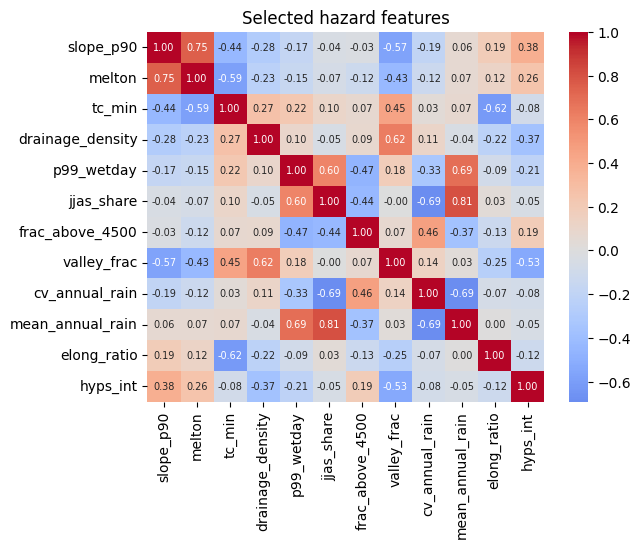

In [ ]:
from scipy.stats import skew
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
PRIORITY = ["slope_p90","melton","tc_min","drainage_density","p99_wetday","heavy_days","max3d","jjas_share",
            "frac_above_4500","valley_frac","twi_mean","cv_annual_rain","mean_annual_rain","elong_ratio",
            "steep30_frac","relief_ratio","slope_mean","hyps_int"] + (["n_lakes"] if "n_lakes" in cat else [])
class Prep:
    def fit(self, X, priority, keep_n=5, thr=.85):
        corr = X[priority].corr().abs().fillna(0); kept = []
        for f_ in priority:
            if len(kept) < keep_n or all(corr.loc[f_, k] < thr for k in kept): kept.append(f_)
        self.kept = kept; Xk = X[kept]
        self.logc = [c for c in kept if Xk[c].min() >= 0 and abs(skew(Xk[c])) > 1]
        self.sc = StandardScaler().fit(self._log(Xk)); return self
    def _log(self, X): X = X[self.kept].copy(); X[self.logc] = np.log1p(X[self.logc]); return X
    def transform(self, X): return self.sc.transform(self._log(X))
prep = Prep().fit(cat, PRIORITY); Xh = prep.transform(cat)
print("hazard features kept:", prep.kept, "\nlog1p:", prep.logc, "| matrix", Xh.shape)
sns.heatmap(cat[prep.kept].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}); plt.title("Selected hazard features"); plt.show()

## 7. Compare algorithms and pick K (silhouette, Davies-Bouldin, BIC, bootstrap stability)

In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering, HDBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score as ARI
KS = range(4, 9); rng = np.random.default_rng(SEED); n = len(Xh); ss = min(3000, n)
fit_km  = lambda X, k: KMeans(k, n_init=10, random_state=SEED).fit(X)
fit_gmm = lambda X, k: GaussianMixture(k, covariance_type="full", n_init=3, reg_covar=1e-4, random_state=SEED).fit(X)
rows = []
for k in KS:
    km, gm = fit_km(Xh, k), fit_gmm(Xh, k); ward = AgglomerativeClustering(k, linkage="ward").fit_predict(Xh)
    for name, model, lb in [("kmeans", km, km.labels_), ("gmm", gm, gm.predict(Xh))]:
        stab = np.mean([ARI(lb, (fit_km if name == "kmeans" else fit_gmm)(Xh[s], k).predict(Xh))
                        for s in [rng.choice(n, int(.8 * n), replace=False) for _ in range(8)]])
        rows.append(dict(model=name, k=k, sil=silhouette_score(Xh, lb, sample_size=ss, random_state=SEED),
                         db=davies_bouldin_score(Xh, lb), bic=gm.bic(Xh) if name == "gmm" else np.nan, stability=stab,
                         min_size=np.bincount(lb).min(), ARI_vs_ward=ARI(lb, ward)))
res = pd.DataFrame(rows); print(res.round(3).to_string(index=False))
hd = HDBSCAN(min_cluster_size=max(20, n // 100)).fit(Xh)
print("\nHDBSCAN:", hd.labels_.max() + 1, "clusters | noise (anomalous catchments):", round((hd.labels_ == -1).mean() * 100, 1), "%")
K_OVERRIDE = None
okk = res[(res.model == "kmeans") & (res.stability >= .7) & (res.min_size >= 20)]
K = K_OVERRIDE or int((okk if len(okk) else res[res.model == "kmeans"]).sort_values("sil").iloc[-1].k)
print("chosen K =", K)

 model  k   sil    db       bic  stability  min_size  ARI_vs_ward
kmeans  4 0.184 1.673       NaN      0.949       282        0.471
   gmm  4 0.145 1.998 58249.598      0.837       476        0.394
kmeans  5 0.186 1.614       NaN      0.905       219        0.535
   gmm  5 0.122 2.196 56110.219      0.825       436        0.393
kmeans  6 0.181 1.596       NaN      0.938       179        0.480
   gmm  6 0.119 2.533 53890.093      0.701       355        0.310
kmeans  7 0.183 1.571       NaN      0.953       178        0.453
   gmm  7 0.128 1.932 53460.445      0.728       285        0.367
kmeans  8 0.178 1.541       NaN      0.833       179        0.508
   gmm  8 0.107 2.321 50236.994      0.722       189        0.355

HDBSCAN: 2 clusters | noise (anomalous catchments): 69.9 %
chosen K = 5


## 8. Final model: Gaussian Mixture (soft membership = classification uncertainty), regime naming
The `hazard_index` only **orders** the clusters; Section 10 shows it is *not* validated as an event predictor, so clusters are later renamed to descriptive regimes (R1–R5).

ARI(GMM, KMeans) = 0.406 | borderline share: 1.2 %
cascade_risk  High   Low  Moderate
haz_tier                          
Low            420    46        68
Moderate       379    39        72
High            99  1260        19
Very high      294   229       142


,n,hazard_index,area_km2,elev_mean,slope_p90,melton,drainage_density,tc_min,p99_wetday,max3d,heavy_days,jjas_share,frac_above_4500,pop_total,pop_near_channel
h_rank,,,,,,,,,,,,,,,
0,534,0.34,49.44,4837.959961,35.92,0.29,0.50,48.93,45.46,65.160004,0.09,0.41,0.74,170.36,104.98
1,490,0.35,51.29,4771.000000,30.14,0.22,0.60,57.23,50.22,67.940002,0.29,0.38,0.75,197.87,133.52
2,436,0.55,56.35,2124.669922,22.43,0.14,0.61,84.77,88.38,169.460007,2.89,0.77,0.23,13880.19,9773.53
3,942,0.56,49.94,1849.260010,34.68,0.27,0.51,47.99,71.90,137.750000,1.54,0.67,0.00,7038.15,4152.85
4,665,0.62,57.33,4201.330078,46.07,0.39,0.53,45.36,66.03,134.059998,1.63,0.66,0.46,1250.32,785.23


A1 [Low rain-terrain hazard] alpine/cold-arid, low rain extremes, very steep slopes | SNOWMELT/GLOF-PRONE (not in hazard index)
A2 [Moderate rain-terrain hazard] alpine/cold-arid, low rain extremes, steep slopes | SNOWMELT/GLOF-PRONE (not in hazard index)
A3 [High rain-terrain hazard] mid-hill, high rain extremes, gentle slopes
A4 [High rain-terrain hazard] mid-hill, moderate rain extremes, steep slopes
A5 [Very high rain-terrain hazard] alpine/cold-arid, moderate rain extremes, very steep slopes | SNOWMELT/GLOF-PRONE (not in hazard index)


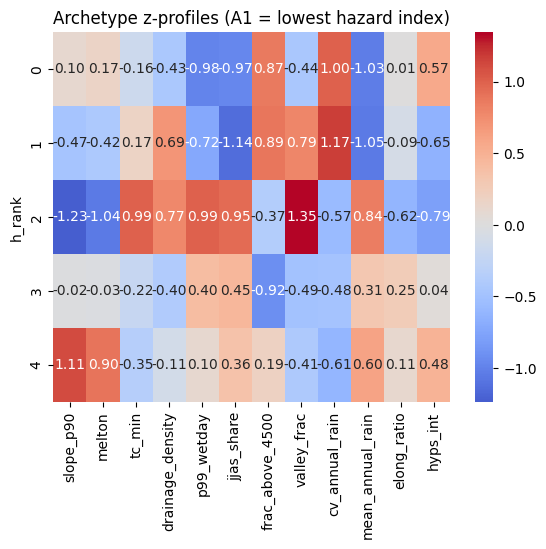

In [ ]:
gmm = fit_gmm(Xh, K); P = gmm.predict_proba(Xh); lbl = P.argmax(1)
cat["conf"] = P.max(1); cat["entropy"] = -(P * np.log(P + 1e-12)).sum(1) / np.log(K)
cat["borderline"] = cat.conf < .6; cat["outlier"] = (hd.labels_ == -1) if hd.labels_.max() >= 0 else False
print("ARI(GMM, KMeans) =", round(ARI(lbl, fit_km(Xh, K).labels_), 3), "| borderline share:", round(cat.borderline.mean() * 100, 1), "%")


pct = lambda s: s.rank(pct=True)
cat["inv_tc"] = 1 / cat.tc_min
resp = pd.concat([pct(cat[c]) for c in ["slope_p90","melton","drainage_density","inv_tc"]], axis=1).mean(1)
rainx = pd.concat([pct(cat[c]) for c in ["p99_wetday","max3d","heavy_days"]], axis=1).mean(1)
cat["hazard_index"] = .5 * resp + .5 * rainx
order = pd.Series(cat.hazard_index.values).groupby(lbl).mean().sort_values().index
rank_of = {c: i for i, c in enumerate(order)}; cat["h_rank"] = [rank_of[c] for c in lbl]
rank_map = np.array([rank_of[c] for c in range(K)])
TIERS = ["Low", "Moderate", "High", "Very high"]
tier_of_rank = lambda r: np.digitize((np.asarray(r) + .5) / K, [.25, .5, .75])
cat["haz_tier"] = tier_of_rank(cat.h_rank)

Z = pd.DataFrame(Xh, columns=prep.kept, index=cat.index).groupby(cat.h_rank).mean()

cat["cascade_risk"] = pd.cut(cat.frac_above_4500, [-.01, .2, .5, 1.01], labels=["Low", "Moderate", "High"]).astype(str)
if "n_lakes" in cat: cat.loc[cat.n_lakes > 0, "cascade_risk"] = "High"
def describe(r):
    m = cat[cat.h_rank == r]
    elev = ["foothill", "mid-hill", "high-hill", "alpine/cold-arid"][np.digitize(m.elev_mean.mean(), [1000, 2500, 4000])]
    rn = ["low", "moderate", "high"][np.digitize(m.max3d.mean(), [100, 150])]
    sl = ["gentle", "steep", "very steep"][np.digitize(m.slope_p90.mean(), [25, 35])]
    tag = " | SNOWMELT/GLOF-PRONE (not in hazard index)" if m.frac_above_4500.mean() >= .3 else ""
    return f"{elev}, {rn} rain extremes, {sl} slopes{tag}"
names = {r: f"A{r+1} [{TIERS[tier_of_rank(r)]} rain-terrain hazard] {describe(r)}" for r in range(K)}
cat["archetype"] = cat.h_rank.map(names)
print(pd.crosstab(cat.haz_tier.map(dict(enumerate(TIERS))), cat.cascade_risk).reindex(TIERS))
prof = cat.groupby("h_rank")[["hazard_index","area_km2","elev_mean","slope_p90","melton","drainage_density","tc_min",
                               "p99_wetday","max3d","heavy_days","jjas_share","frac_above_4500"] + EXPO_COLS].mean()
prof.insert(0, "n", cat.h_rank.value_counts().sort_index()); display(prof.round(2)); print(*names.values(), sep="\n")
sns.heatmap(Z, cmap="coolwarm", center=0, annot=True, fmt=".2f"); plt.title("Archetype z-profiles (A1 = lowest hazard index)"); plt.show()

## 9. Exposure clusters → hazard × exposure score
The priority classes made here are **superseded in Section 10b** (restricted to the populated belt, top 5 % / 10 %). The exposure index and `priority_score` computed here are still used.

In [ ]:
if HAS_EXPO:
    Xe_raw = np.log1p(cat[EXPO_COLS]); Xe = StandardScaler().fit_transform(Xe_raw)
    e_km = KMeans(3, n_init=10, random_state=SEED).fit(Xe)
    eo = pd.Series(Xe_raw.mean(1).values).groupby(e_km.labels_).mean().sort_values().index
    cat["exp_tier"] = pd.Series(e_km.labels_).map({c: i for i, c in enumerate(eo)}).values
    cat["exposure_index"] = pd.concat([pct(cat[c]) for c in EXPO_COLS], axis=1).mean(1)
    cat["priority_score"] = cat.hazard_index * cat.exposure_index
    sp = cat.priority_score.rank(pct=True); h, e = cat.haz_tier, cat.exp_tier
    P1 = (sp >= .90) & (h >= 2)
    P2 = (sp >= .70) & (h >= 1) & ~P1
    P3 = ((sp >= .40) | (e == 2)) & ~P1 & ~P2
    cat["priority"] = np.select([P1, P2, P3], ["P1 Critical", "P2 High", "P3 Watch"], "P4 Routine")
    print(pd.crosstab(cat.haz_tier.map(dict(enumerate(TIERS))), cat.exp_tier.map({0:"Exp Low",1:"Exp Med",2:"Exp High"}), margins=True))
else:
    cat["priority"] = np.select([cat.haz_tier >= 3, cat.haz_tier == 2, cat.haz_tier == 1], ["P1 Critical","P2 High","P3 Watch"], "P4 Routine")
    cat["priority_score"] = cat.hazard_index; print("No exposure data: priority = hazard tier only")
cat.loc[(cat.cascade_risk == "High") & (cat.priority == "P4 Routine"), "priority"] = "P3 Watch"
print(cat.priority.value_counts().sort_index())

exp_tier   Exp High  Exp Low  Exp Med   All
haz_tier                                   
High           1103      218       57  1378
Low              25      185      324   534
Moderate          9      157      324   490
Very high       203       65      397   665
All            1340      625     1102  3067
priority
P1 Critical     304
P2 High         617
P3 Watch       1861
P4 Routine      285
Name: count, dtype: int64


## 10. Validation against real events (Uttarakhand footprint, 5 km buffer for approximate points)
Event files cover **Uttarakhand only**, so validation is restricted to that footprint, then to the populated rain-fed belt (500–3500 m). Reported: AUC with bootstrap CI, baselines, exposure-only check, event rate by regime, lift of P1+P2.

In [ ]:
from sklearn.metrics import roc_auc_score
from scipy.spatial import cKDTree
assert EV_ALL.exists() and EV_TOWN.exists(), "put events_all.csv and events_town_only.csv in /content"
ev_all, ev_town = pd.read_csv(EV_ALL), pd.read_csv(EV_TOWN)
rng = np.random.default_rng(SEED); VAL = {}
pts = cKDTree(np.c_[cat.lat, cat.lon])

def label_events(ev, buf_km=5):
    """1 if catchment has >=1 event. 'town' = exact catchment; 'approx' = all catchments within buf_km."""
    hit = pd.Series(0, index=cat.index)
    for _, r in ev.iterrows():
        if r.precision == "town":
            l_, *_ = to_lab([r.lon], [r.lat])
            if l_[0] in hit.index: hit[l_[0]] = 1
        else:
            hit.iloc[pts.query_ball_point([r.lat, r.lon], buf_km / 111.0)] = 1
    return hit

def auc_ci(y, s, n=300):
    y, s = np.asarray(y), np.asarray(s); b = []
    for _ in range(n):
        i = rng.choice(len(y), len(y))
        if 0 < y[i].sum() < len(i): b.append(roc_auc_score(y[i], s[i]))
    return roc_auc_score(y, s), np.percentile(b, 2.5), np.percentile(b, 97.5)

box  = cat.lat.between(29.2, 31.1) & cat.lon.between(77.9, 80.7)
belt = box & cat.elev_mean.between(500, 3500)
SCORES = [s for s in ["hazard_index", "slope_p90", "p99_wetday", "max3d", "exposure_index", "priority_score"] if s in cat]
Y = {"all": label_events(ev_all), "town_only": label_events(ev_town)}
cat["n_events"] = Y["all"]; cat["in_event_footprint"] = box

for zone, mask in [("footprint", box), ("belt", belt)]:
    for nm, y in Y.items():
        yy = y[mask]; print(f"\n[{zone} | {nm}] catchments: {int(mask.sum())} | with event: {int(yy.sum())}")
        VAL[f"{zone}_{nm}"] = dict(n_catchments=int(mask.sum()), n_event_catchments=int(yy.sum()), auc={})
        for s in SCORES:
            a, lo, hi = auc_ci(yy, cat.loc[mask, s]); VAL[f"{zone}_{nm}"]["auc"][s] = dict(auc=a, lo=lo, hi=hi)
            print(f"  {s:15s} AUC {a:.3f}  (95% CI {lo:.3f}-{hi:.3f})")


[footprint | all] catchments: 865 | with event: 82
  hazard_index    AUC 0.483  (95% CI 0.423-0.539)
  slope_p90       AUC 0.513  (95% CI 0.454-0.578)
  p99_wetday      AUC 0.460  (95% CI 0.394-0.529)
  max3d           AUC 0.446  (95% CI 0.372-0.516)
  exposure_index  AUC 0.709  (95% CI 0.659-0.758)
  priority_score  AUC 0.703  (95% CI 0.646-0.757)

[footprint | town_only] catchments: 865 | with event: 25
  hazard_index    AUC 0.473  (95% CI 0.380-0.567)
  slope_p90       AUC 0.501  (95% CI 0.382-0.622)
  p99_wetday      AUC 0.486  (95% CI 0.360-0.624)
  max3d           AUC 0.506  (95% CI 0.359-0.635)
  exposure_index  AUC 0.772  (95% CI 0.683-0.848)
  priority_score  AUC 0.730  (95% CI 0.643-0.828)

[belt | all] catchments: 605 | with event: 78
  hazard_index    AUC 0.513  (95% CI 0.453-0.579)
  slope_p90       AUC 0.574  (95% CI 0.497-0.632)
  p99_wetday      AUC 0.443  (95% CI 0.377-0.517)
  max3d           AUC 0.460  (95% CI 0.384-0.521)
  exposure_index  AUC 0.595  (95% CI 0.528-

In [ ]:

y = Y["all"]
if "exposure_index" in cat and "exp_tier" in cat:
    ex = box & (cat.exp_tier == 2)
    print("exposure_index AUC (footprint):", round(roc_auc_score(y[box], cat.loc[box, "exposure_index"]), 3))
    print(f"hazard_index AUC among high-exposure catchments: {roc_auc_score(y[ex], cat.loc[ex, 'hazard_index']):.3f}  (n={int(ex.sum())}, events={int(y[ex].sum())})")
t = cat[box].assign(ev=y[box])
print(t.groupby("archetype").ev.agg(n="size", events="sum", rate="mean").round(3))
print(t.groupby(pd.cut(t.elev_mean, [0, 1000, 2000, 3000, 4000, 9000])).ev.agg(n="size", events="sum", rate="mean").round(3))

exposure_index AUC (footprint): 0.709
hazard_index AUC among high-exposure catchments: 0.512  (n=591, events=79)
                                                      n  events   rate
archetype                                                             
A2 [Moderate rain-terrain hazard] alpine/cold-a...    1       1  1.000
A3 [High rain-terrain hazard] mid-hill, high ra...  140      13  0.093
A4 [High rain-terrain hazard] mid-hill, moderat...  503      63  0.125
A5 [Very high rain-terrain hazard] alpine/cold-...  221       5  0.023
                n  events   rate
elev_mean                       
(0, 1000]      58       5  0.086
(1000, 2000]  400      52  0.130
(2000, 3000]  115      21  0.183
(3000, 4000]   73       4  0.055
(4000, 9000]  219       0  0.000


### 10b. Regimes, belt-restricted priority classes and action table

In [ ]:

REGIME = {r: f"R{r+1} " + describe(r).split(" | ")[0] for r in range(K)}
cat["regime"] = cat.h_rank.map(REGIME)
print(cat.groupby("regime").agg(n=("elev_mean", "size"), elev=("elev_mean", "mean"), slope_p90=("slope_p90", "mean")).round(0))


cat["populated"] = cat.elev_mean.between(500, 3500)
pb = cat.populated
rk = cat.loc[pb, "priority_score"].rank(pct=True)
cat["priority"] = "P4 Routine"
cat.loc[rk.index[rk >= .95], "priority"] = "P1 Critical"
cat.loc[rk.index[(rk >= .90) & (rk < .95)], "priority"] = "P2 High"
cat.loc[rk.index[(rk >= .70) & (rk < .90)], "priority"] = "P3 Watch"
cat["cascade_watch"] = (~pb) & (cat.cascade_risk == "High")
cat.loc[cat.cascade_watch, "priority"] = "P3 Watch"
print(cat.priority.value_counts().sort_index())


p12 = cat.priority.isin(["P1 Critical", "P2 High"])
fb = belt; share, cap = p12[fb].mean(), Y["all"][fb & p12].sum() / Y["all"][fb].sum()
print(f"\nP1+P2 = {share:.1%} of belt catchments, capture {cap:.1%} of event catchments | lift {cap/share:.2f}")
rate = cat[box].assign(ev=Y["all"][box]).groupby("regime").ev.agg(n="size", events="sum", rate="mean").round(3)
print("\nEvent rate by regime (Uttarakhand footprint):"); print(rate)
VAL["priority"] = dict(p12_share_of_belt=share, p12_event_capture=cap, lift=cap / share)
VAL["event_rate_by_regime"] = rate.reset_index().to_dict("records")


def action(r):
    share = r.get("pop_near_channel", 0) / max(r.get("pop_total", 1), 1)
    if r.priority in ("P1 Critical", "P2 High"):
        if share >= 0.6: return "Survey channel encroachment; restrict/relocate building in channel margin; rain gauge + siren"
        return "Early-warning siren + rain gauge; evacuation routes and community drills"
    if r.cascade_watch: return "Cascade watch: satellite / glacial-lake monitoring (not validated by event data)"
    if r.priority == "P3 Watch": return "Include in district alert; field survey of channel encroachment"
    return "Routine monitoring"
cat["action"] = cat.apply(action, axis=1)


cols = ["lat", "lon", "regime", "priority", "priority_score", "action", "conf", "borderline", "cascade_risk"] + [c for c in EXPO_COLS if c in cat]
top = cat[p12].sort_values("priority_score", ascending=False)[cols]
top.head(50).to_csv(OUT / "top50_action_table.csv", index_label="catchment_id")
cat.groupby(["priority", "action"]).size().rename("n").to_csv(OUT / "action_summary.csv")
display(top.head(10).round(2))

                                                      n    elev  slope_p90
regime                                                                    
R1 alpine/cold-arid, low rain extremes, very st...  534  4838.0       36.0
R2 alpine/cold-arid, low rain extremes, steep s...  490  4771.0       30.0
R3 mid-hill, high rain extremes, gentle slopes      436  2125.0       22.0
R4 mid-hill, moderate rain extremes, steep slopes   942  1849.0       35.0
R5 alpine/cold-arid, moderate rain extremes, ve...  665  4201.0       46.0
priority
P1 Critical      71
P2 High          70
P3 Watch       1472
P4 Routine     1454
Name: count, dtype: int64

P1+P2 = 8.9% of belt catchments, capture 10.3% of event catchments | lift 1.15

Event rate by regime (Uttarakhand footprint):
                                                      n  events   rate
regime                                                                
R2 alpine/cold-arid, low rain extremes, steep s...    1       1  1.000
R3 mid-hill, high ra

,lat,lon,regime,priority,priority_score,action,conf,borderline,cascade_risk,pop_total,pop_near_channel
l,,,,,,,,,,,
1847,32.19,76.36,"R3 mid-hill, high rain extremes, gentle slopes",P1 Critical,0.82,Survey channel encroachment; restrict/relocate...,1.0,False,Low,37815.13,33107.17
1846,32.21,76.32,"R3 mid-hill, high rain extremes, gentle slopes",P1 Critical,0.82,Survey channel encroachment; restrict/relocate...,1.0,False,Low,58678.54,39198.95
1799,32.27,76.29,"R3 mid-hill, high rain extremes, gentle slopes",P1 Critical,0.78,Survey channel encroachment; restrict/relocate...,1.0,False,Low,31968.92,23155.09
1981,32.11,76.59,"R3 mid-hill, high rain extremes, gentle slopes",P1 Critical,0.78,Survey channel encroachment; restrict/relocate...,1.0,False,Low,19621.63,13089.04
1820,32.20,76.48,"R5 alpine/cold-arid, moderate rain extremes, v...",P1 Critical,0.78,Survey channel encroachment; restrict/relocate...,1.0,False,Low,15595.72,10681.92
1920,32.06,76.71,"R3 mid-hill, high rain extremes, gentle slopes",P1 Critical,0.76,Survey channel encroachment; restrict/relocate...,1.0,False,Low,23650.60,16490.50
1816,32.21,76.43,"R5 alpine/cold-arid, moderate rain extremes, v...",P1 Critical,0.75,Survey channel encroachment; restrict/relocate...,1.0,False,Low,12726.33,9290.16
2059,32.11,76.50,"R3 mid-hill, high rain extremes, gentle slopes",P1 Critical,0.75,Survey channel encroachment; restrict/relocate...,1.0,False,Low,93482.05,67039.23
1813,32.27,76.22,"R3 mid-hill, high rain extremes, gentle slopes",P1 Critical,0.72,Survey channel encroachment; restrict/relocate...,1.0,False,Low,26882.79,17908.13


## 11. Temporal shift: re-assign every catchment using 2015-19 vs 2021-25 rainfall
Trend significance uses **Benjamini–Hochberg FDR** (raw p<0.1 over thousands of catchments is mostly chance).

In [ ]:
def archetype_rank(rain_df):
    X = cat[prep.kept].copy()
    for c in RF.columns:
        if c in X: X[c] = rain_df[c].values
    return np.array([rank_of[c] for c in gmm.predict(prep.transform(X))])
cat["rank_early"], cat["rank_late"] = archetype_rank(RAIN_E), archetype_rank(RAIN_L)
cat["shift"] = cat.rank_late - cat.rank_early
print(pd.crosstab(cat.rank_early + 1, cat.rank_late + 1, rownames=["early A"], colnames=["late A"]))
print(f"shifted up: {(cat['shift'] > 0).mean():.1%} | shifted down: {(cat['shift'] < 0).mean():.1%}")

p = cat.rx3_p.fillna(1).values; n_ = len(p); o = np.argsort(p)
q = np.empty(n_); q[o] = np.minimum.accumulate((p[o] * n_ / (np.arange(n_) + 1))[::-1])[::-1]
cat["rx3_q"] = np.minimum(q, 1)
raw_up = int(((cat.rx3_trend > 0) & (cat.rx3_p < .1)).sum())
cat["trend_sig_up"] = (cat.rx3_trend > 0) & (cat.rx3_q < .1)
print(f"raw p<0.1 rising: {raw_up} | expected by chance ~{int(.05 * n_)} | after FDR: {int(cat.trend_sig_up.sum())}")
cat["emerging"] = (cat["shift"] > 0) & cat.trend_sig_up
print("emerging-risk catchments (shift up + FDR-significant rising trend):", int(cat.emerging.sum()))
VAL["trend"] = dict(raw_sig=raw_up, after_fdr=int(cat.trend_sig_up.sum()), emerging=int(cat.emerging.sum()))

late A     1    2    3    4    5
early A                         
1        248  219    1    3   56
2          7  450    6    0    7
3          0    7  430    0    1
4          0    0    3  933    6
5          2   48    9    6  625
shifted up: 9.7% | shifted down: 2.7%
raw p<0.1 rising: 219 | expected by chance ~153 | after FDR: 0
emerging-risk catchments (shift up + FDR-significant rising trend): 0


## 12. Explain archetypes (random-forest surrogate + SHAP)

surrogate 5-fold CV accuracy: 0.911


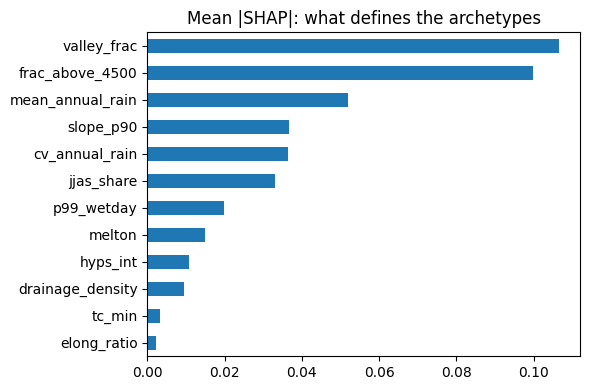

In [ ]:
import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
Xr = cat[prep.kept]; rf = RandomForestClassifier(300, random_state=SEED, n_jobs=-1)
print("surrogate 5-fold CV accuracy:", cross_val_score(rf, Xr, cat.h_rank, cv=5).mean().round(3))
rf.fit(Xr, cat.h_rank)
sv = shap.TreeExplainer(rf).shap_values(Xr.sample(min(1500, len(Xr)), random_state=SEED))
sv = np.stack(sv, -1) if isinstance(sv, list) else sv
imp = pd.Series(np.abs(sv).mean((0, 2)), index=prep.kept).sort_values()
imp.plot.barh(figsize=(6, 4), title="Mean |SHAP|: what defines the archetypes"); plt.tight_layout(); plt.show()

PC1-3 variance: [0.282 0.275 0.127] | cumulative: [0.282 0.557 0.684]
                   PC1   PC2   PC3
slope_p90        -0.41 -0.17  0.08
melton           -0.39 -0.16 -0.07
tc_min            0.36  0.16  0.47
drainage_density  0.31  0.11 -0.20
p99_wetday       -0.05  0.45 -0.01
jjas_share       -0.17  0.46  0.08
frac_above_4500   0.19 -0.31  0.19
valley_frac       0.41  0.17 -0.21
cv_annual_rain    0.27 -0.36 -0.10
mean_annual_rain -0.20  0.46  0.08
elong_ratio      -0.24 -0.07 -0.55
hyps_int         -0.22 -0.17  0.56


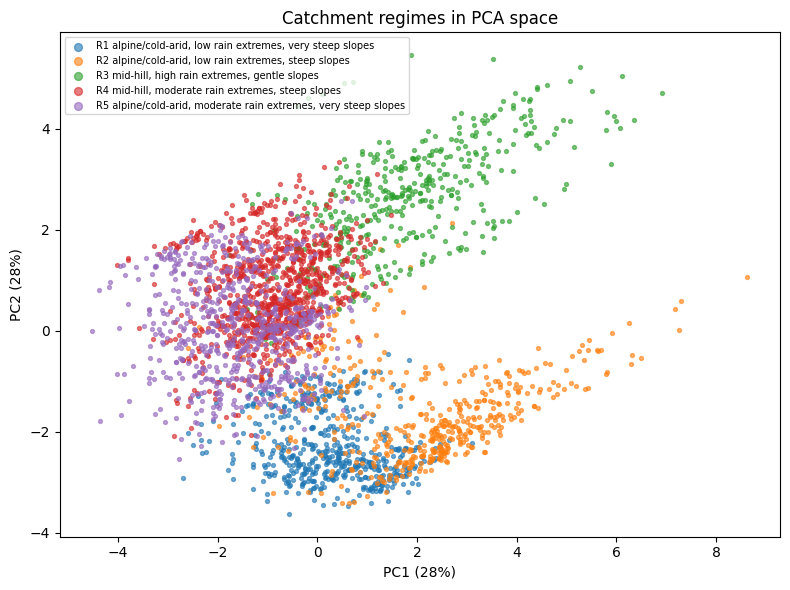

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(3, random_state=SEED).fit(Xh); Zp = pca.transform(Xh); ev_ = pca.explained_variance_ratio_
print("PC1-3 variance:", ev_.round(3), "| cumulative:", ev_.cumsum().round(3))
print(pd.DataFrame(pca.components_.T, index=prep.kept, columns=["PC1", "PC2", "PC3"]).round(2))
fig, ax = plt.subplots(figsize=(8, 6))
for r_, nm in sorted(REGIME.items()):
    m = (cat.h_rank == r_).values; ax.scatter(Zp[m, 0], Zp[m, 1], s=8, alpha=.6, label=nm)
ax.set_xlabel(f"PC1 ({ev_[0]:.0%})"); ax.set_ylabel(f"PC2 ({ev_[1]:.0%})"); ax.legend(fontsize=7, markerscale=2)
ax.set_title("Catchment regimes in PCA space"); plt.tight_layout(); plt.savefig(OUT / "pca_regimes.png", dpi=170); plt.show()
VAL["pca_variance"] = [float(v) for v in ev_]

## 13. Catchment-specific rain alert levels + alert burden
The tiers here are **alert-sensitivity tiers** (how aggressively to alert), not validated hazard levels. Each tier has (watch, warning) percentiles of wet-day rainfall; a cap raises any threshold that would fire too often (warning fatigue). Daily 0.25° rainfall cannot resolve cloudbursts, so these are daily-scale watch levels. Illustrative: tune once better event data exist.

In [ ]:
TIER_Q = {0: (.99, .998), 1: (.97, .993), 2: (.96, .99), 3: (.95, .985)}
MAX_WATCH_DAYS, MAX_WARN_DAYS = 4.0, 1.0
qs = sorted({q for v in TIER_Q.values() for q in v})
wetq = rain.where(rain >= 2.5).quantile(qs, "TIME")
cell_idx = RF.index
stacked = rain.stack(cell=("LATITUDE", "LONGITUDE")); stk = stacked.values; ny = len(YEARS)
ci = {tuple(k): i for i, k in enumerate(stacked.cell.values)}
col = np.array([ci[tuple(cell_idx[c])] for c in cat.cell])
srt = np.sort(stk, axis=0)
cap = lambda days: srt[-(int(days * ny) + 1), :]
thr = lambda c, q: float(wetq.sel(quantile=q, LATITUDE=cell_idx[c][0], LONGITUDE=cell_idx[c][1]))
cat["watch_mm"] = [max(thr(c, TIER_Q[t][0]), cap(MAX_WATCH_DAYS)[j]) for c, t, j in zip(cat.cell, cat.haz_tier, col)]
cat["warn_mm"]  = [max(thr(c, TIER_Q[t][1]), cap(MAX_WARN_DAYS)[j]) for c, t, j in zip(cat.cell, cat.haz_tier, col)]
cat["watch_days_yr"] = [(stk[:, j] >= t).sum() / ny for j, t in zip(col, cat.watch_mm)]
cat["warn_days_yr"]  = [(stk[:, j] >= t).sum() / ny for j, t in zip(col, cat.warn_mm)]
cat["imd_orange_days_yr"] = [(stk[:, j] >= 115.6).sum() / ny for j in col]
alert = cat.groupby(cat.haz_tier.map(dict(enumerate(TIERS))))[["watch_mm","warn_mm","watch_days_yr","warn_days_yr","imd_orange_days_yr"]].mean().reindex(TIERS)
display(alert.round(1))

,watch_mm,warn_mm,watch_days_yr,warn_days_yr,imd_orange_days_yr
haz_tier,,,,,
Low,45.5,61.7,0.5,0.1,0.0
Moderate,33.7,54.8,1.4,0.4,0.0
High,50.4,77.6,3.6,0.9,0.3
Very high,44.3,66.2,4.1,1.1,0.1


## 14. Maps, decision tables and frontend exports (CSV / GeoTIFF / simplified GeoJSON / `frontend_data.json`)

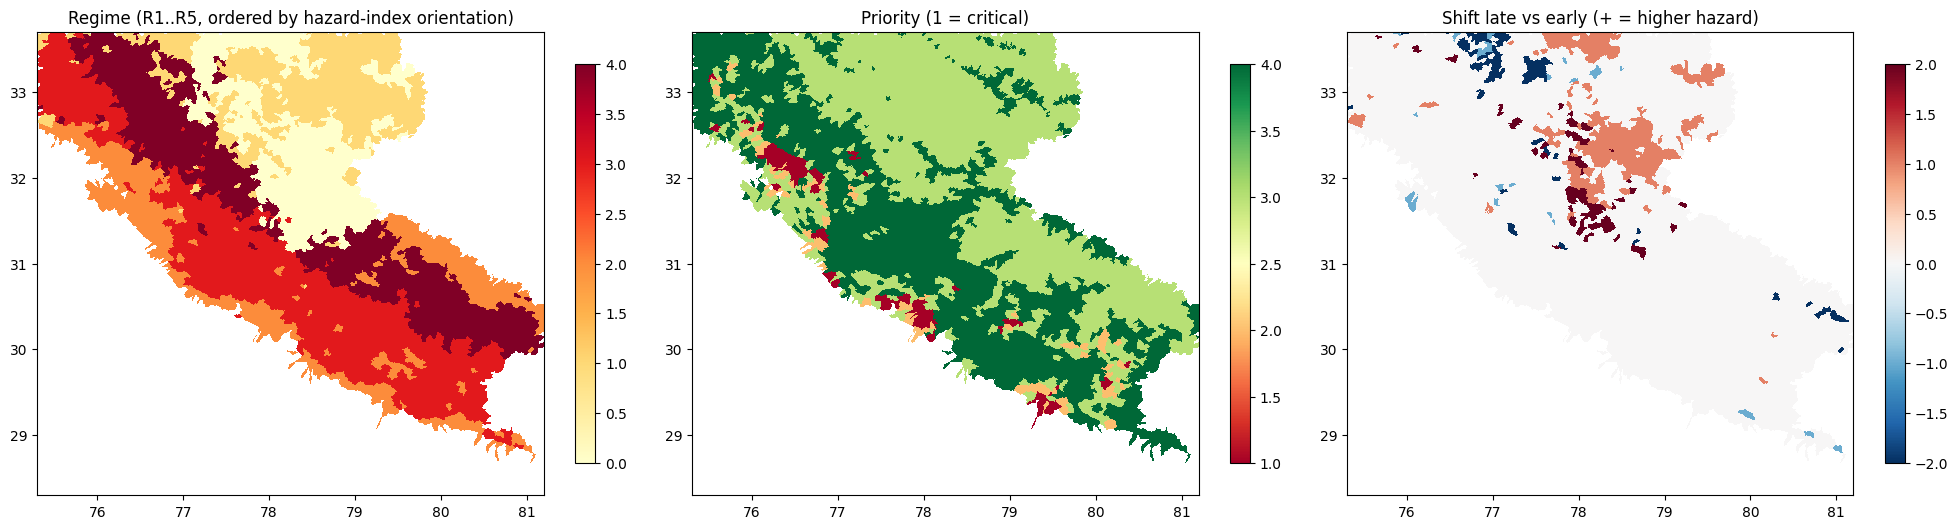

saved to /content/out


In [ ]:
def to_raster(series):
    v = np.full(N, np.nan); v[series.index.values] = series.values
    out = np.full(lab.shape, np.nan, dtype="float32"); out[ok] = v[lab[ok]]; return out
ext = [lon_c[0], lon_c[-1], lat_c[-1], lat_c[0]]
fig, ax = plt.subplots(1, 3, figsize=(20, 6))
for a, (s, t, cm) in zip(ax, [(cat.h_rank, "Regime (R1..R5, ordered by hazard-index orientation)", "YlOrRd"),
                              (cat.priority.str[1].astype(int), "Priority (1 = critical)", "RdYlGn"),
                              (cat["shift"].clip(-2, 2), "Shift late vs early (+ = higher hazard)", "RdBu_r")]):
    im = a.imshow(to_raster(s), extent=ext, cmap=cm, interpolation="nearest"); a.set_title(t); plt.colorbar(im, ax=a, shrink=.7)
plt.tight_layout(); plt.savefig(OUT/"maps.png", dpi=170); plt.show()

keep = ["lat","lon","area_km2","up_area_km2","elev_mean","archetype","haz_tier","hazard_index","conf","borderline","outlier",
        "cascade_risk","priority","priority_score","watch_mm","warn_mm","rx3_trend","rx3_p","shift","emerging","regime","populated","cascade_watch","action","in_event_footprint","n_events"] + EXPO_COLS
cat[keep].to_csv(OUT/"catchment_risk_table.csv", index_label="catchment_id")
cat.sort_values("priority_score", ascending=False).head(100)[keep].to_csv(OUT/"top100_priority_catchments.csv", index_label="catchment_id")
prof.to_csv(OUT/"archetype_profiles.csv"); alert.to_csv(OUT/"alert_thresholds_by_tier.csv"); res.to_csv(OUT/"model_selection.csv", index=False)
for nm, s in [("hazard_rank", cat.h_rank), ("priority", cat.priority.str[1].astype(int))]:
    with rasterio.open(OUT/f"{nm}.tif", "w", driver="GTiff", height=Hc, width=Wc, count=1, dtype="float32",
                       crs="EPSG:4326", transform=tr_c, nodata=np.nan) as dst: dst.write(to_raster(s), 1)
try:
    import geopandas as gpd, shapely.geometry as sg
    from rasterio.features import shapes
    lab_i = np.where(np.isin(lab, cat.index.values), lab, -1).astype("int32")
    polys = [dict(catchment_id=int(v), geometry=sg.shape(g_)) for g_, v in shapes(lab_i, mask=lab_i >= 0, transform=tr_c)]
    gpd.GeoDataFrame(polys, crs=4326).dissolve("catchment_id").join(cat[keep]).pipe(lambda g: g.set_geometry(g.geometry.simplify(0.002))).to_file(OUT/"catchments_risk.geojson", driver="GeoJSON")
except Exception as e: print("GeoJSON export skipped:", e)
print("saved to", OUT)

In [ ]:

def clean(o):
    if isinstance(o, dict):  return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if not np.isfinite(o) else float(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return o
reg_prof = cat.groupby("regime").agg(n=("elev_mean", "size"), elev_mean=("elev_mean", "mean"), slope_p90=("slope_p90", "mean"),
            p99_wetday=("p99_wetday", "mean"), max3d=("max3d", "mean"), pop_total=("pop_total", "mean")).round(2).reset_index()
cols_c = ["lat", "lon", "area_km2", "elev_mean", "regime", "priority", "priority_score", "cascade_risk", "cascade_watch", "populated",
          "action", "conf", "borderline", "watch_mm", "warn_mm", "pop_total", "pop_near_channel", "shift", "emerging"]
frontend = dict(
    title="Himalayan catchment flash-flood regimes and priority triage",
    region="Uttarakhand + Himachal Pradesh (event validation: Uttarakhand only)",
    summary=dict(n_catchments=int(len(cat)), priority_counts=cat.priority.value_counts().sort_index().to_dict(),
                 n_cascade_watch=int(cat.cascade_watch.sum()), n_emerging=int(cat.emerging.sum())),
    regimes=reg_prof.to_dict("records"),
    validation=VAL,
    top50=json.loads(top.head(50).rename_axis("catchment_id").reset_index().to_json(orient="records")),
    catchments=json.loads(cat[[c for c in cols_c if c in cat]].round(3).rename_axis("catchment_id").reset_index().to_json(orient="records")),
    limitations=["Event records are Uttarakhand-only (no Himachal), exposure-biased and mostly approximate in location.",
                 "0.25 deg daily IMD rainfall cannot resolve sub-daily cloudbursts; rainfall extremes showed no event discrimination.",
                 "Regimes describe terrain-rainfall character and support exposure-targeted triage; they are not event predictors.",
                 "Alpine and glacial/snowmelt hazard is flagged (cascade watch) but not validated.",
                 "A 10-year rainfall record gives no statistically robust trend after multiple-testing correction."])
json.dump(clean(frontend), open(OUT / "frontend_data.json", "w"), allow_nan=False)
print("frontend_data.json:", round((OUT / "frontend_data.json").stat().st_size / 1e6, 2), "MB")
try:
    import shutil; shutil.make_archive("/content/flood_outputs", "zip", OUT)
    from google.colab import files; files.download("/content/flood_outputs.zip")
except Exception as e: print("zip/download skipped:", e)

frontend_data.json: 1.58 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
cat["event_all"], cat["event_town"] = Y["all"], Y["town_only"]
FEAT = ["lat","lon","area_km2","up_area_km2","elev_mean","slope_p90","melton","drainage_density","tc_min","p99_wetday","max3d",
        "heavy_days","jjas_share","frac_above_4500","hazard_index","exposure_index","priority_score","h_rank","regime","priority",
        "populated","cascade_watch","cascade_risk","pop_total","pop_near_channel","event_all","event_town","in_event_footprint",
        "watch_mm","warn_mm","watch_days_yr","warn_days_yr","imd_orange_days_yr","rx3_trend","rx3_q","shift","conf","borderline","action"]
cat[[c for c in FEAT if c in cat]].to_csv(OUT/"catchment_features.csv", index_label="catchment_id")